<a href="https://colab.research.google.com/github/arelidiaz371-glitch/M-todos-num-ricos-segunda-tarea/blob/main/m%C3%A9todos%20num%C3%A9ricos%202da%20tarea.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Método de iteración de punto fijo

Análisis numérico — Algoritmo 2.2 de Burden

Objetivo: Implementar el método de iteración de punto fijo y aplicarlo a la ecuación no lineal presentada en el Ejemplo 1 de la página 38 del libro de Burden.
El procedimiento incluye el planteamiento matemático, la implementación del algoritmo, una tabla de aproximaciones sucesivas y gráficas para analizar el comportamiento del método.

1. Planteamiento del problema

Se desea encontrar una aproximación de la raíz de la ecuación no lineal

$$
f(x)=x^3+4x^2-10=0.
$$

De acuerdo con el ejemplo del libro de Burden, se considera inicialmente el intervalo $[1,2]$. Para aplicar el método de punto fijo, es necesario expresar la ecuación en la forma

$$
x=g(x).
$$

Partiendo de la ecuación original, se despeja $x$:

$$
x^3+4x^2=10
$$

$$
4x^2=10-x^3
$$

$$
x^2=\frac{10-x^3}{4}.
$$

Tomando la raíz positiva, se obtiene la función de iteración

$$
\boxed{g(x)=\sqrt{\frac{10-x^3}{4}}}.
$$

Posterior a esto, la fórmula utilizada para generar las aproximaciones sucesivas es

$$
\boxed{p_n=\sqrt{\frac{10-p_{n-1}^3}{4}}}.
$$

Se utilizará una aproximación inicial $p_0=1.5$, una tolerancia de $10^{-4}$ y un máximo de 100 iteraciones. El proceso terminará cuando la diferencia absoluta entre dos aproximaciones consecutivas sea menor que la tolerancia establecida.

2. Implementación del método

Para desarrollar el programa se utilizarán las bibliotecas math, pandas y matplotlib. La primera permite calcular la raíz cuadrada, la segunda facilita la presentación de los resultados en una tabla y la tercera se utilizará para elaborar las gráficas.

In [3]:
import math
import pandas as pd
import matplotlib.pyplot as plt

# de iteración
def g(x):
    return math.sqrt((10 - x**3) / 4)

def f(x):
    return x**3 + 4*x**2 - 10

3. Desarrollo del algoritmo de punto fijo

El método de iteración de punto fijo permite aproximar una solución mediante la aplicación repetida de una función $g$. A partir de una aproximación inicial $p_0$, se calcula cada nuevo valor utilizando

$$
p_n=g(p_{n-1}).
$$

De acuerdo con el Algoritmo 2.2 de Burden, en cada iteración se calcula una nueva aproximación y se compara con la anterior. Si se cumple la condición

$$
|p_n-p_{n-1}|<TOL,
$$

el procedimiento termina y se considera que se alcanzó la tolerancia solicitada. Para evitar un número ilimitado de cálculos, también se establece un máximo de iteraciones.

In [4]:
def punto_fijo(g, p0, tol=1e-4, max_iter=100):
    historial = []
    for i in range(1, max_iter + 1):
        p = g(p0)

        error = abs(p - p0)

        historial.append([i, p0, p, error])
        if error < tol:
            return p, historial, True
        p0 = p

    return p, historial, False

4. Aplicación numérica

Para resolver la ecuación $x^3+4x^2-10=0$, se utiliza la función de iteración definida anteriormente. Los parámetros seleccionados son:

* Aproximación inicial: $p_0=1.5$.
* Tolerancia: $TOL=10^{-4}$.
* Número máximo de iteraciones: $N_0=100$.

Con estos valores se ejecuta el algoritmo y se registran las aproximaciones obtenidas en cada paso.

In [5]:
p0 = 1.5
tol = 1e-4
max_iter = 100

raiz, historial, convergio = punto_fijo(
    g, p0, tol, max_iter
)
tabla = pd.DataFrame(
    historial,
    columns=[
        "Iteración",
        "Aproximación anterior",
        "Nueva aproximación",
        "Error absoluto"
    ]
)

display(
    tabla.style.format({
        "Aproximación anterior": "{:.10f}",
        "Nueva aproximación": "{:.10f}",
        "Error absoluto": "{:.8e}"
    })
)

,Iteración,Aproximación anterior,Nueva aproximación,Error absoluto
0,1,1.5000000000,1.2869537676,2.13046232e-01
1,2,1.2869537676,1.4025408035,1.15587036e-01
2,3,1.4025408035,1.3454583740,5.70824295e-02
3,4,1.3454583740,1.3751702528,2.97118788e-02
4,5,1.3751702528,1.3600941928,1.50760601e-02
5,6,1.3600941928,1.3678469676,7.75277483e-03
6,7,1.3678469676,1.3638870039,3.95996371e-03
7,8,1.3638870039,1.3659167334,2.02972951e-03
8,9,1.3659167334,1.3648782172,1.03851620e-03
9,10,1.3648782172,1.3654100612,5.31843976e-04


5. Representación gráfica

Se elaboran dos gráficas para estudiar la solución. La primera muestra la función original y permite observar dónde cruza el eje horizontal. La segunda representa $y=g(x)$ y la recta $y=x$; su punto de intersección corresponde al punto fijo buscado.

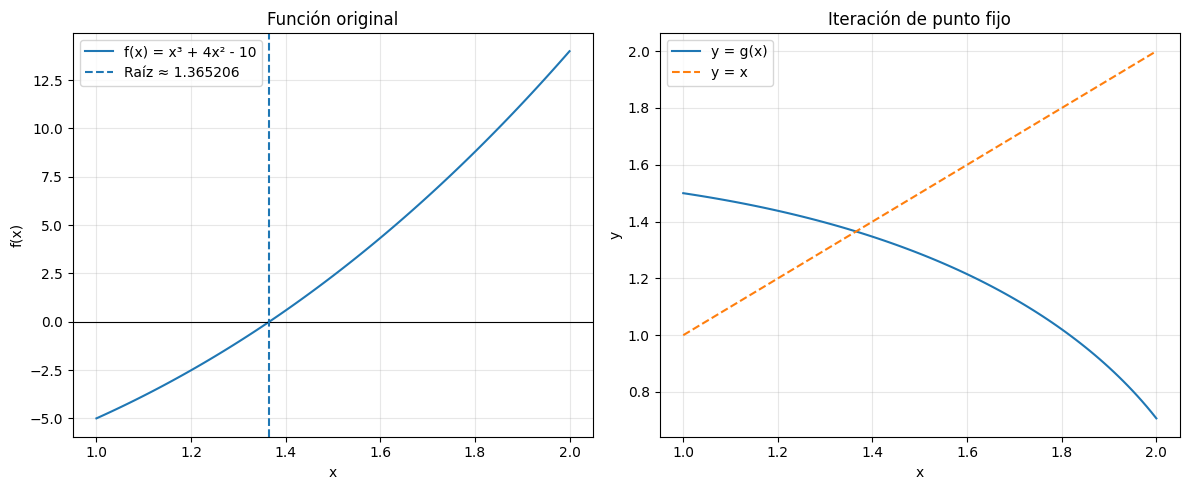

In [6]:
x = [1 + i * 0.01 for i in range(101)]

y_f = [f(v) for v in x]
y_g = [g(v) for v in x]


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(x, y_f, label="f(x) = x³ + 4x² - 10")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(raiz, linestyle="--",
                label=f"Raíz ≈ {raiz:.6f}")
axes[0].set_title("Función original")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(x, y_g, label="y = g(x)")
axes[1].plot(x, x, linestyle="--", label="y = x")
axes[1].set_title("Iteración de punto fijo")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

6. Verificación de los resultados

Una vez finalizadas las iteraciones, se verifica si el método alcanzó la tolerancia establecida. También se evalúa la función original en la aproximación obtenida para calcular el residuo absoluto:

$$
|f(p)|=|p^3+4p^2-10|.
$$

Un residuo pequeño indica que la aproximación satisface la ecuación original con un margen de error reducido.

In [7]:
error_final = historial[-1][3]
residuo = abs(f(raiz))

if convergio:
    print("CONVERGENCIA ALCANZADA")
    print(f"Número de iteraciones: {len(historial)}")
    print(f"Raíz aproximada: {raiz:.10f}")
    print(f"Diferencia final: {error_final:.8e}")
    print(f"Residuo de la función: {residuo:.8e}")
else:
    print("No se alcanzó la tolerancia establecida.")

CONVERGENCIA ALCANZADA
Número de iteraciones: 13
Raíz aproximada: 1.3652058503
Diferencia final: 7.13582274e-05
Residuo de la función: 3.99010468e-04


7. Conclusión

Mediante el método de iteración de punto fijo se obtuvo una aproximación de la raíz de la ecuación no lineal

$$
x^3+4x^2-10=0.
$$

La implementación permitió aplicar de manera iterativa la función $g(x)$ y controlar la precisión mediante la diferencia entre aproximaciones consecutivas. Asimismo, la tabla y las gráficas facilitaron el análisis del comportamiento numérico del procedimiento.

Se comprobó que el algoritmo puede implementarse en Python utilizando funciones, ciclos y condiciones lógicas para automatizar el cálculo y determinar cuándo detener las iteraciones.